In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [2]:

!pip install -q tensorflow-datasets

import tensorflow_datasets as tfds

!pip install -q importlib-resources


print("TensorFlow Datasets version:", tfds.__version__)


TensorFlow Datasets version: 4.9.10


In [3]:
import os

# List files in the current notebook directory
print(os.listdir("/content"))

['.config', 'EuroSAT_RGB.zip', 'sample_data']


In [5]:
import zipfile
import os

zip_path = "/content/EuroSAT_RGB.zip"
extract_path = "/content/EuroSAT"

# Extract the ZIP file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Extracted contents:", os.listdir(extract_path))

Dataset extracted successfully!
Extracted contents: ['EuroSAT_RGB']


In [6]:
os.listdir(extract_path)

['EuroSAT_RGB']

In [7]:
dataset_path = "/content/EuroSAT/EuroSAT_RGB"

# List the contents of the dataset folder
print(os.listdir(dataset_path))

['Industrial', 'Residential', 'Forest', 'SeaLake', 'HerbaceousVegetation', 'AnnualCrop', 'River', 'Highway', 'PermanentCrop', 'Pasture']


In [8]:
import os

# Get class folder names
class_names = sorted(os.listdir(dataset_path))

print("Number of classes:", len(class_names))
print("\nClass names:\n")

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):
        image_count = len([
            file for file in os.listdir(class_path)
            if file.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        print(f"{class_name}: {image_count} images")

Number of classes: 10

Class names:

AnnualCrop: 3000 images
Forest: 3000 images
HerbaceousVegetation: 3000 images
Highway: 2500 images
Industrial: 2500 images
Pasture: 2000 images
PermanentCrop: 2500 images
Residential: 3000 images
River: 2500 images
SeaLake: 3000 images


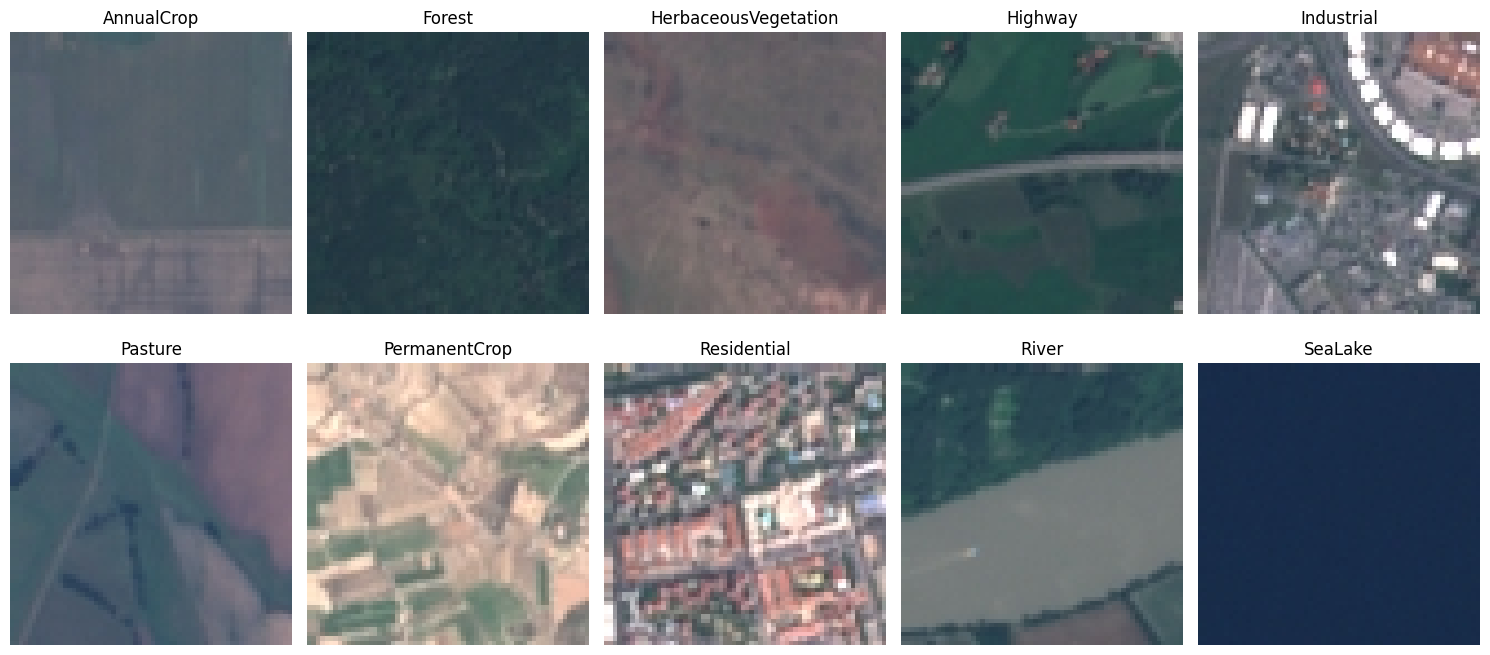

In [9]:
import matplotlib.pyplot as plt
import random
from PIL import Image

# Make results reproducible
random.seed(42)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, class_name in enumerate(class_names):

    class_path = os.path.join(dataset_path, class_name)

    # Get image filenames
    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Select a random image
    image_name = random.choice(image_files)
    image_path = os.path.join(class_path, image_name)

    # Load image
    image = Image.open(image_path)

    # Display image
    ax = axes[i // 5, i % 5]
    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
# Select one image from the AnnualCrop class
sample_class = "AnnualCrop"

sample_folder = os.path.join(dataset_path, sample_class)

sample_image_name = os.listdir(sample_folder)[0]

sample_image_path = os.path.join(
    sample_folder,
    sample_image_name
)

# Load the image
sample_image = Image.open(sample_image_path)

# Convert image to NumPy array
image_array = np.array(sample_image)

# Display image properties
print("Image name:", sample_image_name)
print("Image dimensions:", sample_image.size)
print("Image shape:", image_array.shape)
print("Image data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

Image name: AnnualCrop_298.jpg
Image dimensions: (64, 64)
Image shape: (64, 64, 3)
Image data type: uint8
Minimum pixel value: 43
Maximum pixel value: 255


In [11]:
import glob
from sklearn.model_selection import train_test_split

# Set a global random seed for reproducible dataset splits across all experiments
SEED = 42
DATASET_DIR = "/content/EuroSAT/EuroSAT_RGB"

# 1. Create a deterministic mapping of class names to integer labels (0-9)
class_names = sorted([
    d for d in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, d))
])
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

# 2. Collect all image file paths and their corresponding integer labels
file_paths = []
labels = []

for class_name in class_names:
    class_dir = os.path.join(DATASET_DIR, class_name)
    for img_path in glob.glob(os.path.join(class_dir, "*.jpg")):
        file_paths.append(img_path)
        labels.append(class_to_idx[class_name])

file_paths = np.array(file_paths)
labels = np.array(labels)

# 3. Stratified Split: 70% Train, 15% Validation, 15% Test
# First split: 70% Train, 30% Temp (Validation + Test)
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    file_paths, labels, test_size=0.30, stratify=labels, random_state=SEED
)

# Second split: Split the 30% Temp equally into 15% Validation and 15% Test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, stratify=temp_labels, random_state=SEED
)

# 4. Verify split totals and stratification balance
print(f"Total images found: {len(file_paths)}")
print(f"Training set:   {len(train_paths)} images ({len(train_paths)/len(file_paths):.0%})")
print(f"Validation set: {len(val_paths)} images ({len(val_paths)/len(file_paths):.0%})")
print(f"Testing set:    {len(test_paths)} images ({len(test_paths)/len(file_paths):.0%})\n")

print(f"{'Class Name':<22} | {'Train':<6} | {'Val':<5} | {'Test':<5}")
print("-" * 47)
for idx, name in enumerate(class_names):
    tr_cnt = np.sum(train_labels == idx)
    val_cnt = np.sum(val_labels == idx)
    te_cnt = np.sum(test_labels == idx)
    print(f"{name:<22} | {tr_cnt:<6} | {val_cnt:<5} | {te_cnt:<5}")

Total images found: 27000
Training set:   18900 images (70%)
Validation set: 4050 images (15%)
Testing set:    4050 images (15%)

Class Name             | Train  | Val   | Test 
-----------------------------------------------
AnnualCrop             | 2100   | 450   | 450  
Forest                 | 2100   | 450   | 450  
HerbaceousVegetation   | 2100   | 450   | 450  
Highway                | 1750   | 375   | 375  
Industrial             | 1750   | 375   | 375  
Pasture                | 1400   | 300   | 300  
PermanentCrop          | 1750   | 375   | 375  
Residential            | 2100   | 450   | 450  
River                  | 1750   | 375   | 375  
SeaLake                | 2100   | 450   | 450  


In [12]:
import tensorflow as tf

# Set global TensorFlow seed for reproducibility
tf.random.set_seed(SEED)

IMG_SIZE = 64
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess(path, label):
    """Reads an image file from disk, decodes RGB, sets shape, and normalizes to [0, 1]."""
    img_bytes = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img_bytes, channels=3)
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def create_dataset(paths, labels, is_train=False):
    """Builds an optimized tf.data pipeline from file paths and integer labels."""
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()
    if is_train:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(buffer_size=AUTOTUNE)
    return ds

# Build the three datasets
train_ds = create_dataset(train_paths, train_labels, is_train=True)
val_ds   = create_dataset(val_paths, val_labels, is_train=False)
test_ds  = create_dataset(test_paths, test_labels, is_train=False)

# Verify one batch from the training pipeline
for images_batch, labels_batch in train_ds.take(1):
    print(f"Image batch shape: {images_batch.shape} | dtype: {images_batch.dtype.name}")
    print(f"Label batch shape: {labels_batch.shape} | dtype: {labels_batch.dtype.name}")
    print(f"Normalized pixel range in batch: [{tf.reduce_min(images_batch):.4f}, {tf.reduce_max(images_batch):.4f}]")
    print(f"Total batches -> Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

Image batch shape: (64, 64, 64, 3) | dtype: float32
Label batch shape: (64,) | dtype: int64
Normalized pixel range in batch: [0.0745, 1.0000]
Total batches -> Train: 296 | Val: 64 | Test: 64


In [13]:
def make_augment():
    """Same augmentation block for every model except the Baseline."""
    return [
        layers.RandomFlip("horizontal_and_vertical", seed=SEED),
        layers.RandomRotation(0.2, seed=SEED),
    ]

def make_callbacks(patience_stop=5, patience_lr=2):
    return [
        EarlyStopping(monitor="val_loss", patience=patience_stop,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                          patience=patience_lr, min_lr=1e-6, verbose=1),
    ]

def fine_tune(model, unfreeze_names, lr=1e-5, epochs=12):
    """Stage 2: unfreeze selected backbone layers (BatchNorm stays frozen)."""
    base = next(l for l in model.layers if isinstance(l, tf.keras.Model))
    base.trainable = True
    for l in base.layers:
        is_bn = isinstance(l, layers.BatchNormalization)
        l.trainable = any(n in l.name for n in unfreeze_names) and not is_bn
    model.compile(optimizer=optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     callbacks=make_callbacks(patience_stop=4), verbose=1)

**Custom Baseline Cnn**

In [14]:
from tensorflow.keras import layers, models, optimizers

NUM_CLASSES = len(class_names)

def build_baseline_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    """Builds a simple 3-block Baseline CNN without regularization or augmentation."""
    model = models.Sequential(name="Baseline_CNN", layers=[
        layers.Input(shape=input_shape),

        # Block 1: Basic edges and colors (64x64 -> 32x32)
        layers.Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu", name="conv1"),
        layers.MaxPooling2D(pool_size=(2, 2), name="pool1"),

        # Block 2: Textures and local patterns (32x32 -> 16x16)
        layers.Conv2D(64, kernel_size=(3, 3), padding="same", activation="relu", name="conv2"),
        layers.MaxPooling2D(pool_size=(2, 2), name="pool2"),

        # Block 3: High-level land-cover structures (16x16 -> 8x8)
        layers.Conv2D(128, kernel_size=(3, 3), padding="same", activation="relu", name="conv3"),
        layers.MaxPooling2D(pool_size=(2, 2), name="pool3"),

        # Classifier Head
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", name="dense1"),
        layers.Dense(num_classes, activation="softmax", name="output")
    ])

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

baseline_model = build_baseline_cnn()
baseline_model.summary()

Model: "Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
import time
from tensorflow.keras.callbacks import EarlyStopping

EPOCHS = 30

# Stop training when validation loss stops improving for 5 epochs, and keep the best weights
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("Starting Baseline CNN training...")
start_time = time.time()

baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop],
    verbose=1
)

baseline_train_time = time.time() - start_time

# Extract the best epoch based on minimum validation loss
best_epoch = int(np.argmin(baseline_history.history["val_loss"])) + 1
best_val_loss = baseline_history.history["val_loss"][best_epoch - 1]
best_val_acc = baseline_history.history["val_accuracy"][best_epoch - 1]

print(f"\nTraining completed in {baseline_train_time:.2f} seconds.")
print(f"Best Epoch: {best_epoch} | Best Val Loss: {best_val_loss:.4f} | Best Val Accuracy: {best_val_acc:.4%}")

Starting Baseline CNN training...
Epoch 1/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 21s 46ms/step - accuracy: 0.5028 - loss: 1.3156 - val_accuracy: 0.6728 - val_loss: 0.9350
Epoch 2/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.6863 - loss: 0.8670 - val_accuracy: 0.7558 - val_loss: 0.6648
Epoch 3/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7498 - loss: 0.6857 - val_accuracy: 0.7741 - val_loss: 0.6498
Epoch 4/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7770 - loss: 0.6162 - val_accuracy: 0.8257 - val_loss: 0.5152
Epoch 5/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.8003 - loss: 0.5526 - val_accuracy: 0.7230 - val_loss: 0.7789
Epoch 6/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8255 - loss: 0.4852 - val_accuracy: 0.8079 - val_loss: 0.5482
Epoch 7/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8444 - loss: 0.4305 - val_accuracy: 0.7956 - val_loss: 0.5748
Epoch 8/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accurac

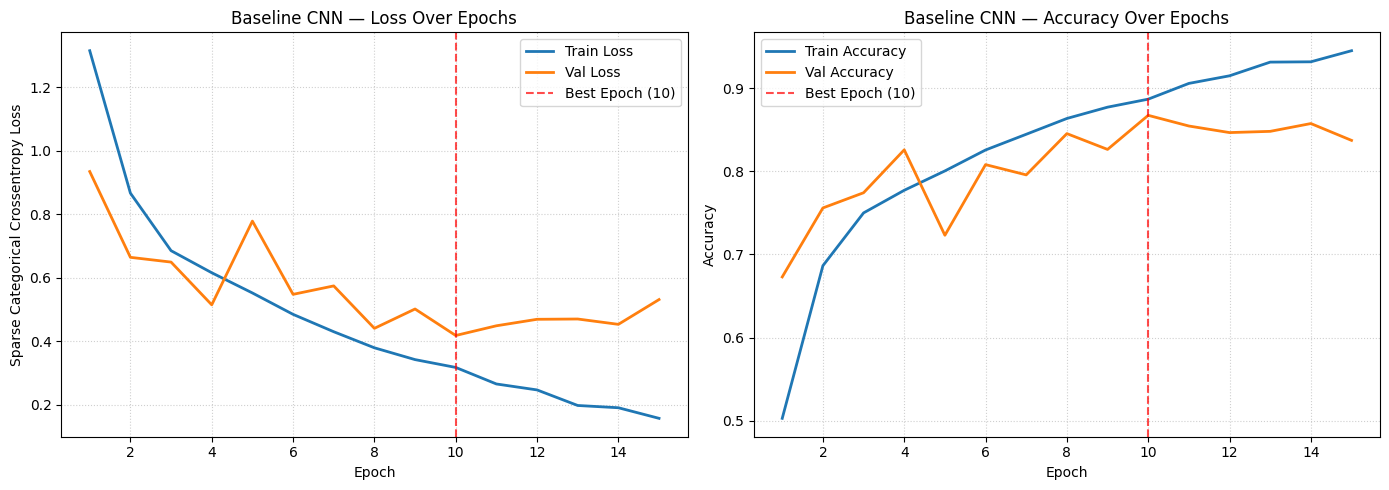

In [16]:
def plot_training_history(history, model_name="Model"):
    """Plots Training vs. Validation Loss and Accuracy with a marker at the best epoch."""
    hist = history.history
    epochs_range = range(1, len(hist["loss"]) + 1)
    best_ep = int(np.argmin(hist["val_loss"])) + 1

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Loss Plot
    ax1.plot(epochs_range, hist["loss"], label="Train Loss", linewidth=2)
    ax1.plot(epochs_range, hist["val_loss"], label="Val Loss", linewidth=2)
    ax1.axvline(best_ep, color="red", linestyle="--", alpha=0.7, label=f"Best Epoch ({best_ep})")
    ax1.set_title(f"{model_name} — Loss Over Epochs")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Sparse Categorical Crossentropy Loss")
    ax1.legend()
    ax1.grid(True, linestyle=":", alpha=0.6)

    # 2. Accuracy Plot
    ax2.plot(epochs_range, hist["accuracy"], label="Train Accuracy", linewidth=2)
    ax2.plot(epochs_range, hist["val_accuracy"], label="Val Accuracy", linewidth=2)
    ax2.axvline(best_ep, color="red", linestyle="--", alpha=0.7, label=f"Best Epoch ({best_ep})")
    ax2.set_title(f"{model_name} — Accuracy Over Epochs")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy")
    ax2.legend()
    ax2.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()

plot_training_history(baseline_history, model_name="Baseline CNN")

In [17]:
import time
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_recall_fscore_support

def evaluate_model(model, dataset, train_time, model_name="Model"):
    """Evaluates a model and prints a detailed performance summary."""
    start_time = time.time()

    y_true = []
    y_pred = []

    # Warm-up inference batch to clear JIT compilation overhead
    for images, labels in dataset.take(1):
        _ = model.predict(images, verbose=0)

    inference_start = time.time()
    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())
    inference_time = time.time() - inference_start

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    precision, recall, _, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")

    total_images = len(y_true)
    latency_ms = (inference_time / total_images) * 1000

    print(f"\n=== {model_name} Evaluation Summary ===")
    print(f"Accuracy:        {acc * 100:.4f}%")
    print(f"Macro F1-Score:  {macro_f1:.4f} (Precision: {precision:.4f} | Recall: {recall:.4f})")
    print(f"Parameters:      {model.count_params():,}")
    print(f"Training Time:   {train_time:.2f} s")
    print(f"Inference Speed: {latency_ms:.3f} ms/image ({inference_time:.2f} s total for {total_images} images)")

    return y_true, y_pred

**Optimized Custom Cnn**

In [18]:
def build_optimized_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    """Builds a deeper, regularized CNN with Augmentation, BatchNorm, Dropout, and GAP."""
    model = models.Sequential(name="Optimized_CNN", layers=[
        layers.Input(shape=input_shape),

        # In-model Data Augmentation (active only during training)
        layers.RandomFlip("horizontal_and_vertical", seed=SEED, name="aug_flip"),
        layers.RandomRotation(0.2, seed=SEED, name="aug_rot"),

        # Block 1: 32 filters (64x64 -> 32x32)
        layers.Conv2D(32, (3, 3), padding="same", use_bias=False, name="b1_conv1"),
        layers.BatchNormalization(name="b1_bn1"),
        layers.Activation("relu", name="b1_act1"),
        layers.Conv2D(32, (3, 3), padding="same", use_bias=False, name="b1_conv2"),
        layers.BatchNormalization(name="b1_bn2"),
        layers.Activation("relu", name="b1_act2"),
        layers.MaxPooling2D((2, 2), name="b1_pool"),
        layers.Dropout(0.15, seed=SEED, name="b1_drop"),

        # Block 2: 64 filters (32x32 -> 16x16)
        layers.Conv2D(64, (3, 3), padding="same", use_bias=False, name="b2_conv1"),
        layers.BatchNormalization(name="b2_bn1"),
        layers.Activation("relu", name="b2_act1"),
        layers.Conv2D(64, (3, 3), padding="same", use_bias=False, name="b2_conv2"),
        layers.BatchNormalization(name="b2_bn2"),
        layers.Activation("relu", name="b2_act2"),
        layers.MaxPooling2D((2, 2), name="b2_pool"),
        layers.Dropout(0.20, seed=SEED, name="b2_drop"),

        # Block 3: 128 filters (16x16 -> 8x8)
        layers.Conv2D(128, (3, 3), padding="same", use_bias=False, name="b3_conv1"),
        layers.BatchNormalization(name="b3_bn1"),
        layers.Activation("relu", name="b3_act1"),
        layers.Conv2D(128, (3, 3), padding="same", use_bias=False, name="b3_conv2"),
        layers.BatchNormalization(name="b3_bn2"),
        layers.Activation("relu", name="b3_act2"),
        layers.MaxPooling2D((2, 2), name="b3_pool"),
        layers.Dropout(0.25, seed=SEED, name="b3_drop"),

        # Block 4: 256 filters (8x8 -> 4x4)
        layers.Conv2D(256, (3, 3), padding="same", use_bias=False, name="b4_conv1"),
        layers.BatchNormalization(name="b4_bn1"),
        layers.Activation("relu", name="b4_act1"),
        layers.Conv2D(256, (3, 3), padding="same", use_bias=False, name="b4_conv2"),
        layers.BatchNormalization(name="b4_bn2"),
        layers.Activation("relu", name="b4_act2"),
        layers.MaxPooling2D((2, 2), name="b4_pool"),
        layers.Dropout(0.30, seed=SEED, name="b4_drop"),

        # Lightweight Classifier Head using Global Average Pooling
        layers.GlobalAveragePooling2D(name="gap"),
        layers.Dense(128, activation="relu", name="dense1"),
        layers.Dropout(0.40, seed=SEED, name="head_drop"),
        layers.Dense(num_classes, activation="softmax", name="output")
    ])

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

optimized_model = build_optimized_cnn()
optimized_model.summary()

Model: "Optimized_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aug_flip (RandomFlip)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_rot (RandomRotation)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv1 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn1 (BatchNormalization)     │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_act1 (Activation)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv2 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn2 (BatchNormalization)     │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_act2 (Activation)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_pool (MaxPooling2D)          │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_drop (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv1 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn1 (BatchNormalization)     │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_act1 (Activation)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv2 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn2 (BatchNormalization)     │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_act2 (Activation)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_pool (MaxPooling2D)          │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_drop (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_conv1 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_bn1 (BatchNormalization)     │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_act1 (Activation)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_conv2 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_bn2 (BatchNormalization)     │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_act2 (Activation)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_pool (MaxPooling2D)          │ (None, 8, 8, 128)      │             

 Total params: 1,209,322 (4.61 MB)

 Trainable params: 1,207,402 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [19]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

EPOCHS = 40

# Callbacks for advanced training control
early_stop_opt = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

print("Starting Optimized CNN training with Data Augmentation & BatchNorm...")
start_time_opt = time.time()

optimized_history = optimized_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop_opt, reduce_lr],
    verbose=1
)

optimized_train_time = time.time() - start_time_opt

# Extract best epoch stats
best_epoch_opt = int(np.argmin(optimized_history.history["val_loss"])) + 1
best_val_loss_opt = optimized_history.history["val_loss"][best_epoch_opt - 1]
best_val_acc_opt = optimized_history.history["val_accuracy"][best_epoch_opt - 1]

print(f"\nTraining completed in {optimized_train_time:.2f} seconds.")
print(f"Best Epoch: {best_epoch_opt} | Best Val Loss: {best_val_loss_opt:.4f} | Best Val Accuracy: {best_val_acc_opt:.4%}")

Starting Optimized CNN training with Data Augmentation & BatchNorm...
Epoch 1/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 29s 66ms/step - accuracy: 0.6472 - loss: 1.0232 - val_accuracy: 0.1481 - val_loss: 4.7852 - learning_rate: 0.0010
Epoch 2/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 34s 60ms/step - accuracy: 0.7528 - loss: 0.7270 - val_accuracy: 0.6711 - val_loss: 1.0738 - learning_rate: 0.0010
Epoch 3/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 18s 61ms/step - accuracy: 0.8023 - loss: 0.5894 - val_accuracy: 0.7175 - val_loss: 0.9087 - learning_rate: 0.0010
Epoch 4/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 18s 60ms/step - accuracy: 0.8270 - loss: 0.5295 - val_accuracy: 0.6612 - val_loss: 1.0751 - learning_rate: 0.0010
Epoch 5/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 18s 61ms/step - accuracy: 0.8599 - loss: 0.4258 - val_accuracy: 0.8089 - val_loss: 0.7249 - learning_rate: 0.0010
Epoch 6/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 18s 60ms/step - accuracy: 0.8678 - loss: 0.4014 - val_accuracy: 0.6798 - val_loss: 1.2904 - learning_rate: 0.0010
Epoch 

In [20]:
# Evaluate Optimized CNN on the Validation Set
opt_val_true, optimized_val_pred = evaluate_model(
    optimized_model, val_ds, optimized_train_time, model_name="2. Optimized CNN"
)


=== 2. Optimized CNN Evaluation Summary ===
Accuracy:        91.6049%
Macro F1-Score:  0.9140 (Precision: 0.9244 | Recall: 0.9104)
Parameters:      1,209,322
Training Time:   384.65 s
Inference Speed: 1.694 ms/image (6.86 s total for 4050 images)


**Depthwise Seperable Cnn**

Our Optimized CNN is accurate, but it relies on standard convolutions which require a heavy amount of computation. In real-world satellite deployment (or on edge devices), we want high accuracy combined with extreme computational efficiency.

What is a Depthwise Separable Convolution?

Pioneered by Google in MobileNet, it breaks a standard convolution layer into two separate, lightweight steps:

Depthwise Convolution: Applies a single spatial filter ($3 \times 3$) to each input channel independently (no cross-channel mixing yet).

Pointwise Convolution: Uses a $1 \times 1$ convolution to combine those channels across depth.

This clever math slashes the parameter count and FLOPs of convolutional layers by 8× to 9× while maintaining nearly identical classification performance!

That is an 86% reduction in model size while maintaining the exact same network depth and structure. That is the magic of Depthwise Separable Convolutions—by splitting standard convolutions into spatial-only and channel-only steps, we strip away redundant calculations without losing feature representation capacity.

In [21]:
from tensorflow.keras import layers, models, optimizers

def build_stable_dscnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    """Depthwise Separable CNN. Input is already in [0, 1], so no Rescaling here."""
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.SeparableConv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.SeparableConv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.5, seed=SEED),
        layers.Dense(num_classes, activation='softmax')
    ], name="Stable_DS_CNN")
    return model

dscnn_model = build_stable_dscnn()

In [22]:
import time
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Create fresh callbacks with clean state
ds_early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)
ds_reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)

# Re-build and compile the stable DS-CNN
dscnn_model = build_stable_dscnn()
dscnn_model.compile(
    optimizer=optimizers.Adam(learning_rate=3e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Re-training Stable DS-CNN cleanly...")
start_time_ds = time.time()

dscnn_history = dscnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[ds_early_stop, ds_reduce_lr],
    verbose=1
)

dscnn_train_time = time.time() - start_time_ds
print(f"DS-CNN Training completed in {dscnn_train_time:.2f} seconds.")

Re-training Stable DS-CNN cleanly...
Epoch 1/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - accuracy: 0.4627 - loss: 1.5904 - val_accuracy: 0.1926 - val_loss: 2.2771 - learning_rate: 3.0000e-04
Epoch 2/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6629 - loss: 0.9696 - val_accuracy: 0.5141 - val_loss: 1.3201 - learning_rate: 3.0000e-04
Epoch 3/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7160 - loss: 0.8186 - val_accuracy: 0.7269 - val_loss: 0.7818 - learning_rate: 3.0000e-04
Epoch 4/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7470 - loss: 0.7236 - val_accuracy: 0.7763 - val_loss: 0.6182 - learning_rate: 3.0000e-04
Epoch 5/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.7699 - loss: 0.6596 - val_accuracy: 0.7165 - val_loss: 0.7830 - learning_rate: 3.0000e-04
Epoch 6/40
292/296 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7816 - loss: 0.6302
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
296/296 ━━━━━━

In [23]:
# Evaluate
ds_val_true, dscnn_val_pred = evaluate_model(
    dscnn_model, val_ds, dscnn_train_time, model_name="3. Depthwise Separable CNN"
)


=== 3. Depthwise Separable CNN Evaluation Summary ===
Accuracy:        89.8272%
Macro F1-Score:  0.8928 (Precision: 0.8929 | Recall: 0.8938)
Parameters:      14,378
Training Time:   160.71 s
Inference Speed: 1.609 ms/image (6.52 s total for 4050 images)


**Transfer Learning**

In [24]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

def build_resnet50_transfer(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    """Builds a ResNet50 transfer learning model with a frozen feature extractor."""

    # 1. Load pretrained ResNet50 without its top classification head
    base_model = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape
    )

    # Freeze the pretrained backbone weights
    base_model.trainable = False

    # 2. Build the new model with preprocessing and a custom head
    model = models.Sequential(name="ResNet50_Transfer", layers=[
        layers.Input(shape=input_shape),

        # ResNet expects inputs scaled differently than [0, 1].
        # Lambda layer to scale [0, 1] back to [-1, 1] or use preprocess_input scaling
        layers.Lambda(lambda x: x * 255.0, name="scale_to_255"),
        layers.Lambda(preprocess_input, name="resnet_preprocess"),

        # Data Augmentation (helpful even with transfer learning)
        layers.RandomFlip("horizontal_and_vertical", seed=SEED),
        layers.RandomRotation(0.2, seed=SEED),

        # Pretrained Feature Extractor Backbone
        base_model,

        # Custom Classifier Head
        layers.GlobalAveragePooling2D(name="resnet_gap"),
        layers.Dense(256, activation="relu", name="resnet_dense1"),
        layers.Dropout(0.4, seed=SEED, name="resnet_drop"),
        layers.Dense(num_classes, activation="softmax", name="resnet_output")
    ])

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

resnet_model = build_resnet50_transfer()
resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ scale_to_255 (Lambda)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocess (Lambda)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 2, 2, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_gap                      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_dense1 (Dense)           │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_drop (Dropout)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_output (Dense)           │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 527,114 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [25]:
# Create fresh callbacks
res_early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)
res_reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)

# Re-build and compile ResNet50 Transfer
resnet_model = build_resnet50_transfer()

print("Re-training ResNet50 Transfer cleanly...")
start_time_res = time.time()
resnet_history = resnet_model.fit(
    train_ds, validation_data=val_ds, epochs=25,
    callbacks=[res_early_stop, res_reduce_lr], verbose=1
)
resnet_train_time = time.time() - start_time_res

Re-training ResNet50 Transfer cleanly...
Epoch 1/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 22s 51ms/step - accuracy: 0.8272 - loss: 0.5641 - val_accuracy: 0.9020 - val_loss: 0.2912 - learning_rate: 0.0010
Epoch 2/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 42ms/step - accuracy: 0.8853 - loss: 0.3481 - val_accuracy: 0.9067 - val_loss: 0.2705 - learning_rate: 0.0010
Epoch 3/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 42ms/step - accuracy: 0.8965 - loss: 0.3099 - val_accuracy: 0.9151 - val_loss: 0.2667 - learning_rate: 0.0010
Epoch 4/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.9039 - loss: 0.2882 - val_accuracy: 0.9106 - val_loss: 0.2629 - learning_rate: 0.0010
Epoch 5/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.9088 - loss: 0.2719 - val_accuracy: 0.9195 - val_loss: 0.2442 - learning_rate: 0.0010
Epoch 6/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.9084 - loss: 0.2714 - val_accuracy: 0.9180 - val_loss: 0.2402 - learning_rate: 0.0010
Epoch 7/25
296/296 ━━━━━━━━━━━━━━━━

In [26]:
# Evaluate
res_val_true, resnet_val_pred = evaluate_model(
    resnet_model, val_ds, resnet_train_time, model_name="4. ResNet50 Transfer"
)


=== 4. ResNet50 Transfer Evaluation Summary ===
Accuracy:        93.4321%
Macro F1-Score:  0.9314 (Precision: 0.9326 | Recall: 0.9308)
Parameters:      24,114,826
Training Time:   335.18 s
Inference Speed: 2.605 ms/image (10.55 s total for 4050 images)


In [27]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

def build_resnet50_upgraded(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    """Builds ResNet50 with 128x128 upscaling and a robust classification head."""
    # Load backbone at 128x128 resolution for optimal feature extraction
    base_model = ResNet50(weights="imagenet", include_top=False, input_shape=(128, 128, 3))
    base_model.trainable = False  # Stage 1: Freeze backbone initially

    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Resizing(128, 128, interpolation='bilinear', name="upscale_128"),
        layers.Lambda(lambda x: x * 255.0, name="scale_to_255"),
        layers.Lambda(resnet_preprocess, name="resnet_preprocessing"),

        # Spatial Data Augmentation
        layers.RandomFlip("horizontal_and_vertical", seed=SEED),
        layers.RandomRotation(0.2, seed=SEED),

        base_model,

        layers.GlobalAveragePooling2D(name="gap"),
        layers.Dense(512, activation='relu', name="dense_head"),
        layers.Dropout(0.5, seed=SEED, name="dropout_head"),
        layers.Dense(num_classes, activation='softmax', name="output_layer")
    ], name="ResNet50_Upgraded")

    return model

# 1. Instantiate and compile for Stage 1 (Head Warm-up)
resnet_upgraded = build_resnet50_upgraded()
resnet_upgraded.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("=== Stage 1: Training Classification Head ===" )
start_time_res1 = time.time()
history_stage1 = resnet_upgraded.fit(
    train_ds, validation_data=val_ds, epochs=8,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6, verbose=1)
    ],
    verbose=1
)
stage1_time = time.time() - start_time_res1

# 2. Stage 2: Unfreeze conv5 block for Deep Fine-Tuning
print("\n=== Stage 2: Fine-Tuning Backbone (conv5_block) ===")
base_model_inst = resnet_upgraded.get_layer("resnet50")
base_model_inst.trainable = True

for layer in base_model_inst.layers:
    if "conv5" not in layer.name:
        layer.trainable = False
    else:
        layer.trainable = True

resnet_upgraded.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5), # Ultra-low LR
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start_time_res2 = time.time()
history_stage2 = resnet_upgraded.fit(
    train_ds, validation_data=val_ds, epochs=12,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
    ],
    verbose=1
)
total_resnet_time = stage1_time + (time.time() - start_time_res2)

=== Stage 1: Training Classification Head ===
Epoch 1/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 45s 125ms/step - accuracy: 0.8778 - loss: 0.3850 - val_accuracy: 0.9351 - val_loss: 0.2080 - learning_rate: 0.0010
Epoch 2/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 33s 113ms/step - accuracy: 0.9213 - loss: 0.2405 - val_accuracy: 0.9336 - val_loss: 0.2040 - learning_rate: 0.0010
Epoch 3/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 33s 113ms/step - accuracy: 0.9296 - loss: 0.2102 - val_accuracy: 0.9454 - val_loss: 0.1725 - learning_rate: 0.0010
Epoch 4/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 34s 114ms/step - accuracy: 0.9333 - loss: 0.2012 - val_accuracy: 0.9452 - val_loss: 0.1675 - learning_rate: 0.0010
Epoch 5/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 34s 113ms/step - accuracy: 0.9414 - loss: 0.1759 - val_accuracy: 0.9499 - val_loss: 0.1642 - learning_rate: 0.0010
Epoch 6/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 34s 114ms/step - accuracy: 0.9411 - loss: 0.1781 - val_accuracy: 0.9479 - val_loss: 0.1634 - learning_rate: 0.0010
Epoch 7/8
296/296 ━━━━━━━━━━━━

In [28]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

def build_mobilenet_transfer(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    """Builds a MobileNetV2 transfer learning model with a frozen feature extractor."""
    base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=input_shape)
    base_model.trainable = False

    model = models.Sequential(name="MobileNetV2_Transfer", layers=[
        layers.Input(shape=input_shape),
        layers.Lambda(lambda x: x * 255.0, name="mobilenet_scale"),
        layers.Lambda(mobilenet_preprocess, name="mobilenet_preprocess"),
        layers.RandomFlip("horizontal_and_vertical", seed=SEED),
        layers.RandomRotation(0.2, seed=SEED),
        base_model,
        layers.GlobalAveragePooling2D(name="mobilenet_gap"),
        layers.Dense(256, activation="relu", name="mobilenet_dense1"),
        layers.Dropout(0.4, seed=SEED, name="mobilenet_drop"),
        layers.Dense(num_classes, activation="softmax", name="mobilenet_output")
    ])

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

mobilenet_model = build_mobilenet_transfer()

# FRESH callbacks for MobileNetV2
early_stop_mb = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1)
reduce_lr_mb = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)

print("Starting MobileNetV2 Transfer Learning training...")
start_time_mb = time.time()

mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[early_stop_mb, reduce_lr_mb],
    verbose=1
)

mobilenet_train_time = time.time() - start_time_mb

/tmp/ipykernel_666/2818731202.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=input_shape)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Starting MobileNetV2 Transfer Learning training...
Epoch 1/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 13s 26ms/step - accuracy: 0.7443 - loss: 0.7871 - val_accuracy: 0.8365 - val_loss: 0.4881 - learning_rate: 0.0010
Epoch 2/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.8149 - loss: 0.5599 - val_accuracy: 0.8541 - val_loss: 0.4275 - learning_rate: 0.0010
Epoch 3/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8287 - loss: 0.5119 - val_accuracy: 0.8526 - val_loss: 0.4139 - learning_rate: 0.0010
Epoch 4/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.8376 - loss: 0.4818 - val_accuracy: 0.8523 - val_loss: 0.4327 - learning_rate: 0.0010
Epoch 5/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8379 - loss: 0.4692 - val_accuracy: 0.8612 - val_loss: 0.3935 - learning_rate: 0.0010
Epoch 6/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.8436 - loss: 0.4540 - val_accuracy: 0.8612 - val_loss: 0.3915 - lea

In [29]:
def build_mobilenet_upgraded(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    base_model = MobileNetV2(weights="imagenet", include_top=False,
                             input_shape=(128, 128, 3))
    base_model.trainable = False
    return models.Sequential(name="MobileNetV2_Upgraded", layers=[
        layers.Input(shape=input_shape),
        layers.Resizing(128, 128, interpolation="bilinear", name="upscale_128"),
        layers.Lambda(lambda x: x * 255.0, name="mobilenet_scale"),
        layers.Lambda(mobilenet_preprocess, name="mobilenet_preprocess"),
        *make_augment(),
        base_model,
        layers.GlobalAveragePooling2D(name="gap"),
        layers.Dense(512, activation="relu", name="dense_head"),
        layers.Dropout(0.5, seed=SEED, name="dropout_head"),
        layers.Dense(num_classes, activation="softmax", name="output_layer"),
    ])

mobilenet_model = build_mobilenet_upgraded()
mobilenet_model.compile(optimizer=optimizers.Adam(1e-3),
                        loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# Stage 1: head only (same budget as ResNet)
mobilenet_history = mobilenet_model.fit(
    train_ds, validation_data=val_ds, epochs=8,
    callbacks=make_callbacks(patience_stop=3, patience_lr=1), verbose=1)

# Stage 2: unfreeze last blocks, same LR/epochs as ResNet
mobilenet_ft_history = fine_tune(mobilenet_model, ["block_15", "block_16", "out"])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 21s 51ms/step - accuracy: 0.8446 - loss: 0.4724 - val_accuracy: 0.9168 - val_loss: 0.2444 - learning_rate: 0.0010
Epoch 2/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8859 - loss: 0.3363
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
296/296 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - accuracy: 0.8929 - loss: 0.3170 - val_accuracy: 0.9133 - val_loss: 0.2534 - learning_rate: 0.0010
Epoch 3/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - accuracy: 0.9105 - loss: 0.2610 - val_accuracy: 0.9333 - val_loss: 0.2043 - learning_rate: 5.0000e-04
Epoch 4/8
295/296 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9229 - loss: 0.2303
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
296/296 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - accuracy: 0.9199 - loss: 0.2354 - val_accuracy: 0.9277 - val_loss: 0.2123 - learning_rate: 5.0000e-04
Epoch 5/8
296/296 ━━━━━━━━━

**Testing**

In [30]:
import time
import numpy as np
from sklearn.metrics import (accuracy_score, f1_score,
                             precision_recall_fscore_support)

def evaluate_model(model, dataset, model_name="Model", verbose=True):
    """Evaluates a model on a dataset. Returns (y_true, y_pred).
    Speed is NOT measured here (predict() overhead makes it misleading);
    use benchmark_latency() below for timing."""
    y_true, y_pred = [], []
    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    y_true, y_pred = np.array(y_true), np.array(y_pred)

    if verbose:
        acc = accuracy_score(y_true, y_pred)
        macro_f1 = f1_score(y_true, y_pred, average="macro")
        prec, rec, _, _ = precision_recall_fscore_support(
            y_true, y_pred, average="macro", zero_division=0)
        print(f"{model_name:<42} Acc: {acc*100:6.2f}% | "
              f"Macro-F1: {macro_f1:.4f} (P: {prec:.4f} | R: {rec:.4f}) | "
              f"Params: {model.count_params():,}")
    return y_true, y_pred


# Trained models (keys kept the same so downstream cells still work)
models_to_evaluate = {
    "1. Baseline CNN": baseline_model,
    "2. Optimized Custom CNN": optimized_model,
    "3. Depthwise Separable CNN (Stable)": dscnn_model,
    "4. ResNet50 Upgraded (Fine-Tuned)": resnet_upgraded,
    "5. MobileNetV2 Fine-Tuned": mobilenet_model,
}

test_evaluation_results = {}

print("=" * 110)
print("TEST SET EVALUATION (single run, 4050 images)")
print("=" * 110)

for name, model_instance in models_to_evaluate.items():
    try:
        y_true, y_pred = evaluate_model(model_instance, test_ds,
                                        model_name=name)
        test_evaluation_results[name] = {"true": y_true, "pred": y_pred}
    except Exception as e:
        print(f"{name:<42} ERROR: {e}")

# ---- Sanity check: every model must see the same labels in the same order ----
ref = next(iter(test_evaluation_results.values()))["true"]
assert all(np.array_equal(ref, r["true"]) for r in test_evaluation_results.values()), \
    "Label order differs between models!"
assert len(ref) == len(test_labels), "Test size mismatch!"

# ---- Summary table ----
print("\n| Model | Test Acc (%) | Macro F1 | Params |")
print("|---|---|---|---|")
for name, r in test_evaluation_results.items():
    acc = accuracy_score(r["true"], r["pred"]) * 100
    f1 = f1_score(r["true"], r["pred"], average="macro")
    print(f"| {name} | {acc:.2f} | {f1:.4f} | "
          f"{models_to_evaluate[name].count_params():,} |")

print("\nAll test evaluations completed!")


Evaluating: 1. Baseline CNN on Test Set

=== 1. Baseline CNN (Test Set) Evaluation Summary ===
Accuracy:        85.6790%
Macro F1-Score:  0.8518 (Precision: 0.8570 | Recall: 0.8525)
Parameters:      1,143,242
Training Time:   0.00 s
Inference Speed: 1.513 ms/image (6.13 s total for 4050 images)

Evaluating: 2. Optimized Custom CNN on Test Set

=== 2. Optimized Custom CNN (Test Set) Evaluation Summary ===
Accuracy:        90.7407%
Macro F1-Score:  0.9051 (Precision: 0.9191 | Recall: 0.9008)
Parameters:      1,209,322
Training Time:   0.00 s
Inference Speed: 1.596 ms/image (6.46 s total for 4050 images)

Evaluating: 3. Depthwise Separable CNN (Stable) on Test Set

=== 3. Depthwise Separable CNN (Stable) (Test Set) Evaluation Summary ===
Accuracy:        88.8148%
Macro F1-Score:  0.8833 (Precision: 0.8843 | Recall: 0.8845)
Parameters:      14,378
Training Time:   0.00 s
Inference Speed: 1.254 ms/image (5.08 s total for 4050 images)

Evaluating: 4. ResNet50 Upgraded (Fine-Tuned) on Test S


Classification Report: 1. Baseline CNN
                      precision    recall  f1-score   support

          AnnualCrop     0.9116    0.8022    0.8534       450
              Forest     0.9550    0.9422    0.9485       450
HerbaceousVegetation     0.7535    0.8422    0.7954       450
             Highway     0.8442    0.6213    0.7158       375
          Industrial     0.9213    0.9360    0.9286       375
             Pasture     0.8078    0.8267    0.8171       300
       PermanentCrop     0.6862    0.8107    0.7433       375
         Residential     0.9453    0.9222    0.9336       450
               River     0.7897    0.8613    0.8240       375
             SeaLake     0.9558    0.9600    0.9579       450

            accuracy                         0.8568      4050
           macro avg     0.8570    0.8525    0.8518      4050
        weighted avg     0.8623    0.8568    0.8567      4050



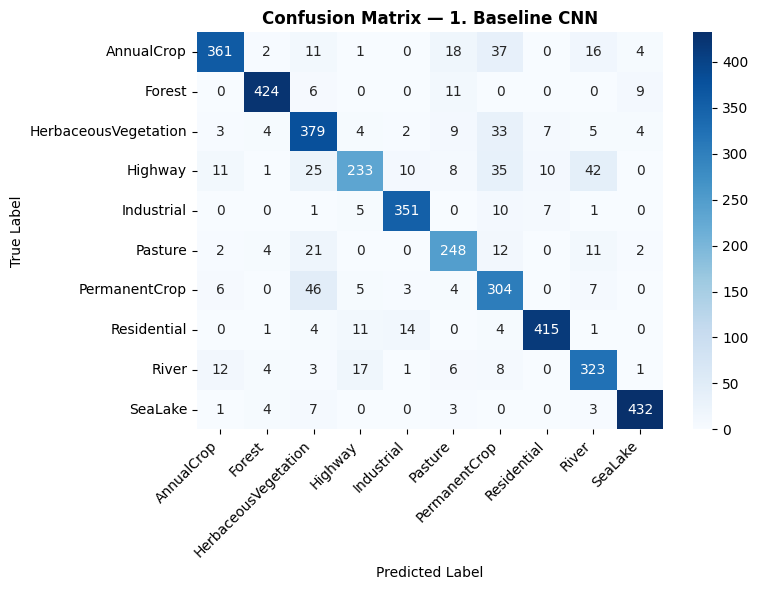


Classification Report: 2. Optimized Custom CNN
                      precision    recall  f1-score   support

          AnnualCrop     0.9824    0.8689    0.9222       450
              Forest     0.8421    0.9956    0.9124       450
HerbaceousVegetation     0.7291    0.9089    0.8091       450
             Highway     0.9264    0.9733    0.9493       375
          Industrial     0.9388    0.9813    0.9596       375
             Pasture     0.9782    0.7467    0.8469       300
       PermanentCrop     0.9067    0.7253    0.8059       375
         Residential     0.9466    0.9844    0.9651       450
               River     0.9506    0.8720    0.9096       375
             SeaLake     0.9907    0.9511    0.9705       450

            accuracy                         0.9074      4050
           macro avg     0.9191    0.9008    0.9051      4050
        weighted avg     0.9161    0.9074    0.9071      4050



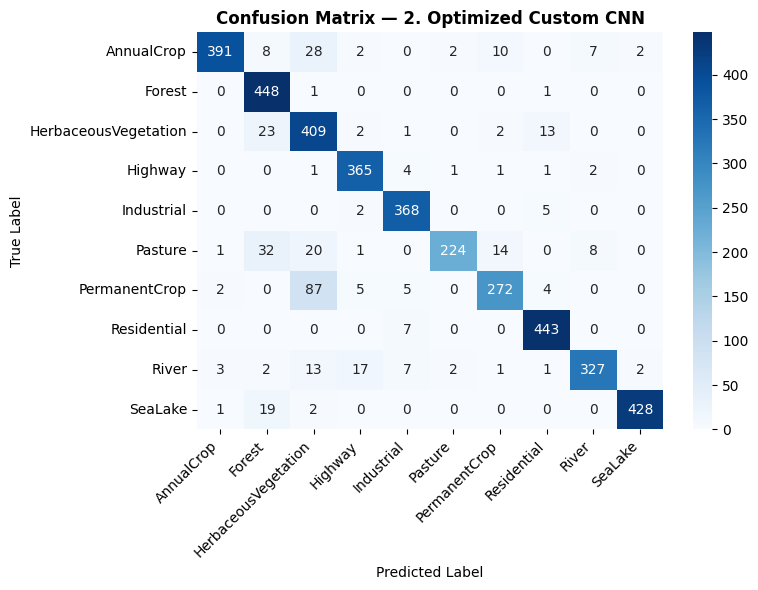


Classification Report: 3. Depthwise Separable CNN (Stable)
                      precision    recall  f1-score   support

          AnnualCrop     0.8993    0.8533    0.8757       450
              Forest     0.9645    0.9667    0.9656       450
HerbaceousVegetation     0.8008    0.8756    0.8365       450
             Highway     0.8457    0.7307    0.7840       375
          Industrial     0.9095    0.9653    0.9366       375
             Pasture     0.8273    0.9100    0.8667       300
       PermanentCrop     0.8043    0.8000    0.8021       375
         Residential     0.9437    0.9689    0.9561       450
               River     0.8659    0.7920    0.8273       375
             SeaLake     0.9822    0.9822    0.9822       450

            accuracy                         0.8881      4050
           macro avg     0.8843    0.8845    0.8833      4050
        weighted avg     0.8885    0.8881    0.8873      4050



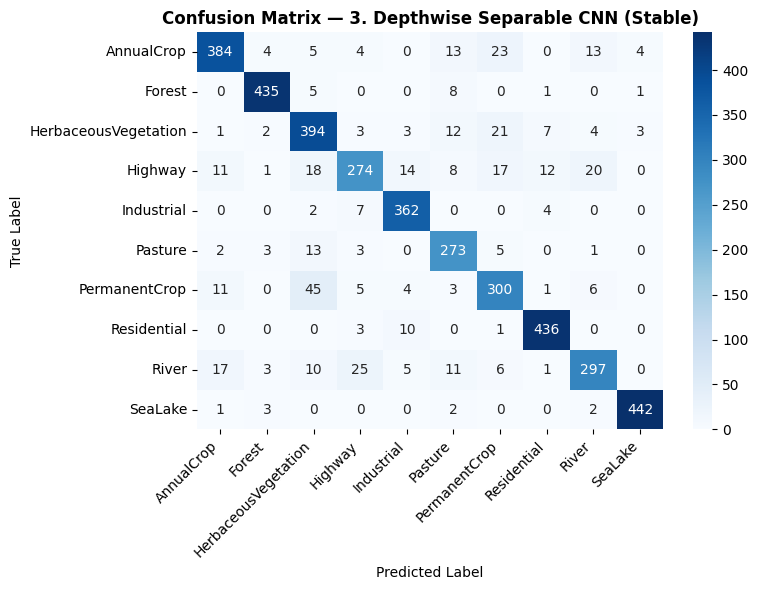


Classification Report: 4. ResNet50 Upgraded (Fine-Tuned)
                      precision    recall  f1-score   support

          AnnualCrop     0.9795    0.9578    0.9685       450
              Forest     0.9756    0.9778    0.9767       450
HerbaceousVegetation     0.9557    0.9578    0.9567       450
             Highway     0.9388    0.9413    0.9401       375
          Industrial     0.9535    0.9840    0.9685       375
             Pasture     0.9570    0.9633    0.9601       300
       PermanentCrop     0.9549    0.9600    0.9574       375
         Residential     0.9887    0.9711    0.9798       450
               River     0.9573    0.9573    0.9573       375
             SeaLake     0.9933    0.9911    0.9922       450

            accuracy                         0.9667      4050
           macro avg     0.9654    0.9662    0.9657      4050
        weighted avg     0.9668    0.9667    0.9667      4050



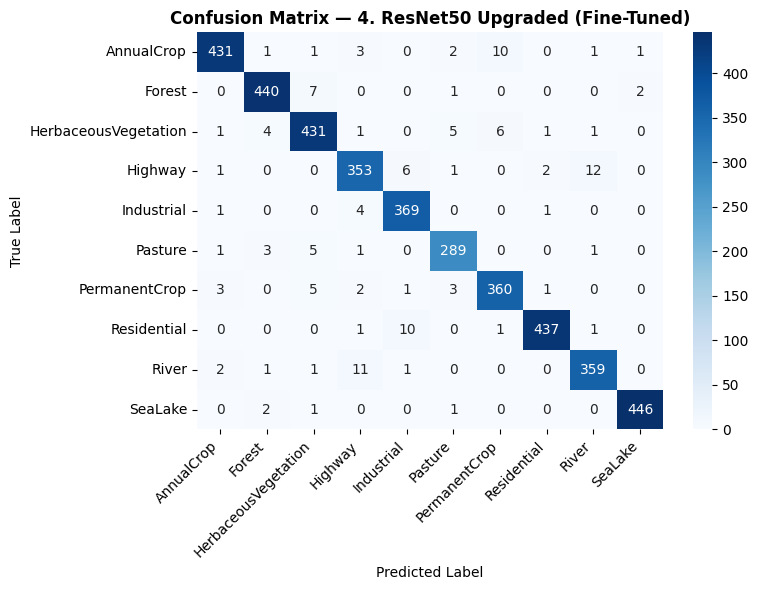


Classification Report: 5. MobileNetV2 Fine-Tuned
                      precision    recall  f1-score   support

          AnnualCrop     0.9446    0.9467    0.9456       450
              Forest     0.9442    0.9778    0.9607       450
HerbaceousVegetation     0.9305    0.9222    0.9263       450
             Highway     0.8889    0.8960    0.8924       375
          Industrial     0.9509    0.9813    0.9659       375
             Pasture     0.9398    0.9367    0.9382       300
       PermanentCrop     0.9517    0.8933    0.9216       375
         Residential     0.9843    0.9756    0.9799       450
               River     0.9029    0.9173    0.9101       375
             SeaLake     0.9865    0.9733    0.9799       450

            accuracy                         0.9437      4050
           macro avg     0.9424    0.9420    0.9421      4050
        weighted avg     0.9439    0.9437    0.9437      4050



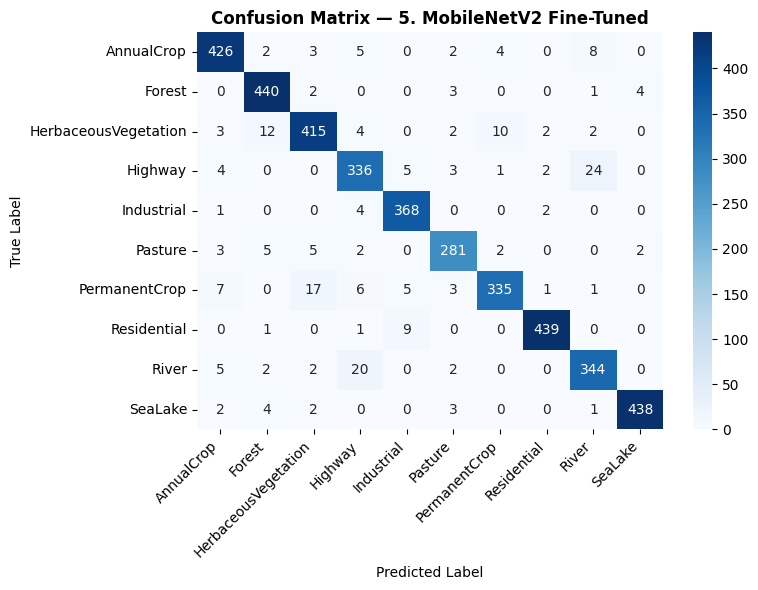

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# EuroSAT 10 Classes
class_names = [
    'AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway',
    'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake'
]

# Assuming test_evaluation_results holds your model predictions from earlier:
# test_evaluation_results = { "Model Name": {"true": y_true, "pred": y_pred}, ... }

for model_name, data in test_evaluation_results.items():
    y_true = data["true"]
    y_pred = data["pred"]

    print(f"\n{'='*60}")
    print(f"Classification Report: {model_name}")
    print(f"{'='*60}")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    # Generate and plot confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix — {model_name}', fontsize=12, fontweight='bold')
    plt.xlabel('Predicted Label', fontsize=10)
    plt.ylabel('True Label', fontsize=10)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [32]:
def get_model_size_mb(model):
    """fp32 weight size only (no optimizer state)."""
    return model.count_params() * 4 / (1024 ** 2)

def get_tflite_size_mb(model, quantize=False):
    """Optional: deployable size after TFLite conversion."""
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    if quantize:
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
    return len(converter.convert()) / (1024 ** 2)

In [33]:
import time, json
from sklearn.metrics import accuracy_score, f1_score

# --- Cache test batches once so the data pipeline is NOT timed ---
test_batches = [(x, y.numpy()) for x, y in test_ds]
n_images = sum(len(y) for _, y in test_batches)

def benchmark_latency(model, batches, warmup=3, repeats=5):
    """Median ms/image over several full passes, model forward pass only."""
    infer = tf.function(lambda x: model(x, training=False))
    # Warm-up (include the last, smaller batch so its shape isn't traced during timing)
    for x, _ in batches[:warmup] + batches[-1:]:
        infer(x).numpy()
    runs = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        for x, _ in batches:
            infer(x).numpy()          # .numpy() forces the GPU to finish
        runs.append((time.perf_counter() - t0) / n_images * 1000)
    return float(np.median(runs)), float(np.std(runs, ddof=1))

print("Devices:", tf.config.list_physical_devices('GPU'))
print(f"Batch size: {BATCH_SIZE} | warm-up batches: 3 | repeats: 5 | images: {n_images}")

# --- Single source of truth for ALL reported numbers ---
bench = {}
for name, m in models_to_evaluate.items():
    lat, lat_sd = benchmark_latency(m, test_batches)
    y_true = test_evaluation_results[name]["true"]
    y_pred = test_evaluation_results[name]["pred"]
    bench[name] = {
        "acc": accuracy_score(y_true, y_pred) * 100,
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "params": m.count_params(),
        "size_mb": get_model_size_mb(m),
        "latency_ms": lat,
        "latency_sd": lat_sd,
    }
    print(f"{name:40s} acc={bench[name]['acc']:.2f}%  lat={lat:.3f}±{lat_sd:.3f} ms")

# Save so you never have to recompute (see the Drive-saving cells)
json.dump(bench, open("benchmark_results.json", "w"), indent=2)

Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Batch size: 64 | warm-up batches: 3 | repeats: 5 | images: 4050
1. Baseline CNN                          acc=85.68%  lat=0.049±0.001 ms
2. Optimized Custom CNN                  acc=90.74%  lat=0.173±0.001 ms
3. Depthwise Separable CNN (Stable)      acc=88.81%  lat=0.065±0.001 ms
4. ResNet50 Upgraded (Fine-Tuned)        acc=96.67%  lat=1.429±0.020 ms
5. MobileNetV2 Fine-Tuned                acc=94.37%  lat=0.507±0.003 ms


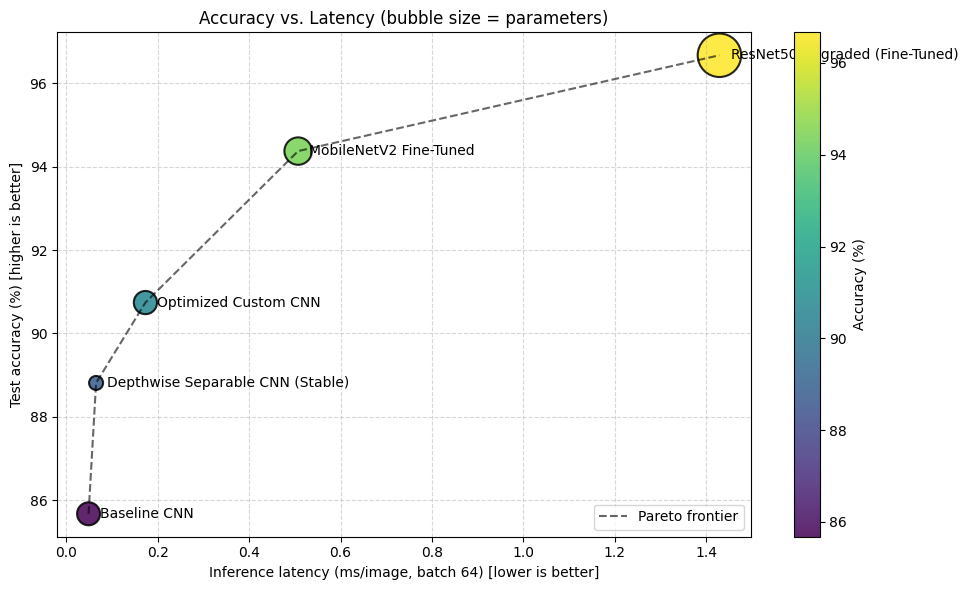

In [34]:
names = list(bench.keys())
lat   = np.array([bench[n]["latency_ms"] for n in names])
acc   = np.array([bench[n]["acc"] for n in names])
par   = np.array([bench[n]["params"] for n in names])

# Pareto frontier: sort by latency, keep a model only if accuracy beats all faster ones
order, best, frontier = np.argsort(lat), -1, []
for i in order:
    if acc[i] > best:
        frontier.append(i); best = acc[i]

sizes = 80 + 900 * np.sqrt(par / par.max())      # sqrt scaling keeps tiny models visible

plt.figure(figsize=(10, 6))
sc = plt.scatter(lat, acc, s=sizes, c=acc, cmap="viridis",
                 alpha=0.85, edgecolors="black", linewidth=1.5)
plt.plot(lat[frontier], acc[frontier], "k--", alpha=0.6, label="Pareto frontier")
for i, n in enumerate(names):
    plt.annotate(n.split(". ", 1)[-1], (lat[i], acc[i]),
                 xytext=(8, -3), textcoords="offset points", fontsize=10)
plt.xlabel("Inference latency (ms/image, batch 64) [lower is better]")
plt.ylabel("Test accuracy (%) [higher is better]")
plt.title("Accuracy vs. Latency (bubble size = parameters)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.colorbar(sc, label="Accuracy (%)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("pareto.png", dpi=200)
plt.show()

In [35]:
print("| Model | Acc (%) | Macro F1 | Params | Size (MB) | Latency (ms/img) |")
print("|---|---|---|---|---|---|")
for n, r in bench.items():
    print(f"| {n} | {r['acc']:.2f} | {r['macro_f1']:.4f} | {r['params']:,} | "
          f"{r['size_mb']:.2f} | {r['latency_ms']:.2f} ± {r['latency_sd']:.2f} |")

| Model | Acc (%) | Macro F1 | Params | Size (MB) | Latency (ms/img) |
|---|---|---|---|---|---|
| 1. Baseline CNN | 85.68 | 0.8518 | 1,143,242 | 4.36 | 0.05 ± 0.00 |
| 2. Optimized Custom CNN | 90.74 | 0.9051 | 1,209,322 | 4.61 | 0.17 ± 0.00 |
| 3. Depthwise Separable CNN (Stable) | 88.81 | 0.8833 | 14,378 | 0.05 | 0.07 ± 0.00 |
| 4. ResNet50 Upgraded (Fine-Tuned) | 96.67 | 0.9657 | 24,641,930 | 94.00 | 1.43 ± 0.02 |
| 5. MobileNetV2 Fine-Tuned | 94.37 | 0.9421 | 2,918,986 | 11.14 | 0.51 ± 0.00 |


In [36]:
from scipy import stats

SEEDS = [42, 1337, 2026]
resnet_seed_accuracies = []

for seed in SEEDS:
    print(f"\n=== ResNet50 Upgraded | Seed {seed} ===")
    tf.keras.utils.set_random_seed(seed)

    model = build_resnet50_upgraded()
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    t0 = time.time()                                   # item 3: real training time
    model.fit(train_ds, validation_data=val_ds, epochs=5, verbose=1)
    train_time = time.time() - t0

    y_true, y_pred = evaluate_model(model, test_ds, train_time=train_time,
                                    model_name=f"ResNet50 Upgraded (Seed {seed})")
    resnet_seed_accuracies.append(accuracy_score(y_true, y_pred) * 100)

# item 2: sample std (ddof=1) and a t-based 95% CI for n=3
accs = np.array(resnet_seed_accuracies)
mean_acc = accs.mean()
std_acc  = accs.std(ddof=1)
ci95     = stats.t.ppf(0.975, df=len(accs) - 1) * std_acc / np.sqrt(len(accs))

print("\nFINAL MULTI-SEED SUMMARY (ResNet50, 5-epoch head-only budget)")
print(f"Accuracies: {[round(a, 2) for a in accs]}")
print(f"Mean ± sample SD: {mean_acc:.2f}% ± {std_acc:.2f}%  (n={len(accs)})")
print(f"95% CI: [{mean_acc - ci95:.2f}%, {mean_acc + ci95:.2f}%]")


=== ResNet50 Upgraded | Seed 42 ===
Epoch 1/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 44s 121ms/step - accuracy: 0.8768 - loss: 0.3866 - val_accuracy: 0.9341 - val_loss: 0.1985
Epoch 2/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 34s 116ms/step - accuracy: 0.9184 - loss: 0.2454 - val_accuracy: 0.9405 - val_loss: 0.1761
Epoch 3/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 34s 113ms/step - accuracy: 0.9311 - loss: 0.2107 - val_accuracy: 0.9449 - val_loss: 0.1633
Epoch 4/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 34s 114ms/step - accuracy: 0.9367 - loss: 0.1900 - val_accuracy: 0.9454 - val_loss: 0.1677
Epoch 5/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 34s 114ms/step - accuracy: 0.9387 - loss: 0.1875 - val_accuracy: 0.9425 - val_loss: 0.1749

=== ResNet50 Upgraded (Seed 42) Evaluation Summary ===
Accuracy:        94.3951%
Macro F1-Score:  0.9414 (Precision: 0.9448 | Recall: 0.9406)
Parameters:      24,641,930
Training Time:   179.17 s
Inference Speed: 3.093 ms/image (12.52 s total for 4050 images)

=== ResNet50 Upgraded | Seed 1337 ===
Epoch 1/5
296